# Ramsey fringes of a spin-1/2
This notebook simulates the time evolution of the spin under the influence of a Ramsey experiment.
It covers:
- Static Spin Hamiltonian
- Ramsey pulse scheme
- Ramsey fringes with various detuning values


In [1]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import scipy.constants as const
from qutip import (
    tensor, qeye, sigmax, sigmay, sigmaz,
    basis, mesolve, sigmam, Qobj, Bloch
)

from spinfinity import ESR, lind, CC, SpinSys, bath, hamil
from spinfinity import helperfunctions as hf

%load_ext autoreload
%autoreload 2

## Static spin Hamiltonian
The static spin Hamiltonian includes an external field in z-direction which defines the quantization axis

In [2]:
spin = SpinSys([0.5])
spin.gfactorvector = [2.0]
spin.B = [0.0, 0.0, 0.5]  # T
spin.BTip = [1e-9, 0.0, 0.0]  # T

hamil.calc_EigEnergies(spin, rebuildH=True)
f_e= float(spin.E_All_inGHz[1] - spin.E_All_inGHz[0])  # GHz

## Continous-wave frequency sweep
Simulating a ESR frequency sweep also reveals the resonance frequency $f_e$. 

In [3]:
ESR.plot_FreqSweep(spin, freq_array = np.linspace(12,16,1000), lw=0.05);

## Constructing collapse operators
We construct $T_1$ collapse operators which determine the relaxometry signal and $T_phi$ collapse operators which have no effect on the relaxometry signal

In [ ]:
# Tunneling Parameters
spin.T = 0.2 # K
spin.V_DC = 0.0  # mV
spin.TipPolarization = [0, 0, 0.5]
spin.U = np.array([0.0])
spin.G_st = 0.1e-9  # S
spin.G_ss = [1e-9]  # S
spin.G_tt = 1 # Allow for tip-tip scattering
spin.b0 = 0.0

# Relaxation
bath.calc_Rates(spin)
bath.calc_Lifetimes(spin)
T1 = (1/spin.T_state_tot[0]+1/spin.T_state_tot[1])**-1*1e9

c_ops_T1 = lind.calc_collapseOperators(spin, threshold_percent=1e-9, recalcRates=True)
print(f"T1 time from tunnel rates: {T1:.2f} ns")

# Decoherence
T_phi = 200  # ns
c_op_Tphi = lind.calc_dephasingOperator(spin, spin_idx=0, T_phi=T_phi)
spin.collapse_ops = c_ops_T1 + [c_op_Tphi]


T1 time from tunnel rates: 1069.08 ns


## Ramsey pulse scheme
For a single free evolution time $\tau$ one can display the expectation value of the spin operators during the pulse sequence

c:\Users\labuser\.conda\envs\SIM2\Lib\site-packages\qutip\core\coefficient.py:199: FutureWarning: The signature f(t, args) is deprecated and will be removed in QuTiP 5.5. Please update your function to the pythonic signature f(t, **kwargs) to maintain compatibility.
  op = FunctionCoefficient(base, args.copy(), style=function_style)


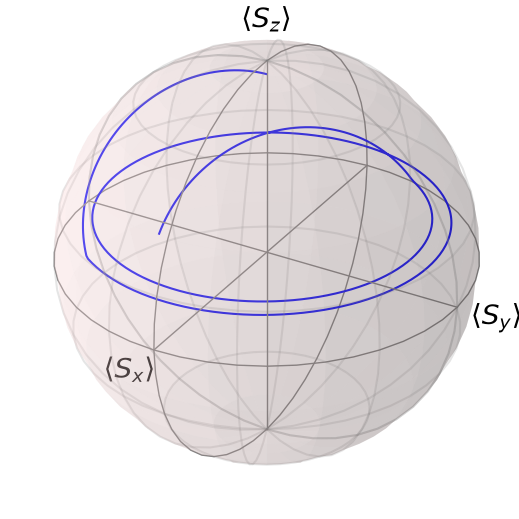

In [6]:
# Parameters and initial state
rho_therm = lind.initialize_thermal(spin)

spin.f_RF = f_e # GHz
spin.RabiRate = 50e-3 # GHz

# Plot a Ramsey Shot
detuning = 50.00e-3 #GHz
spin.f_RF = f_e + detuning
_ = lind.initialize_thermal(spin)

CC.plot_RamseyShot(spin, tau=30);

## Ramsey simulation

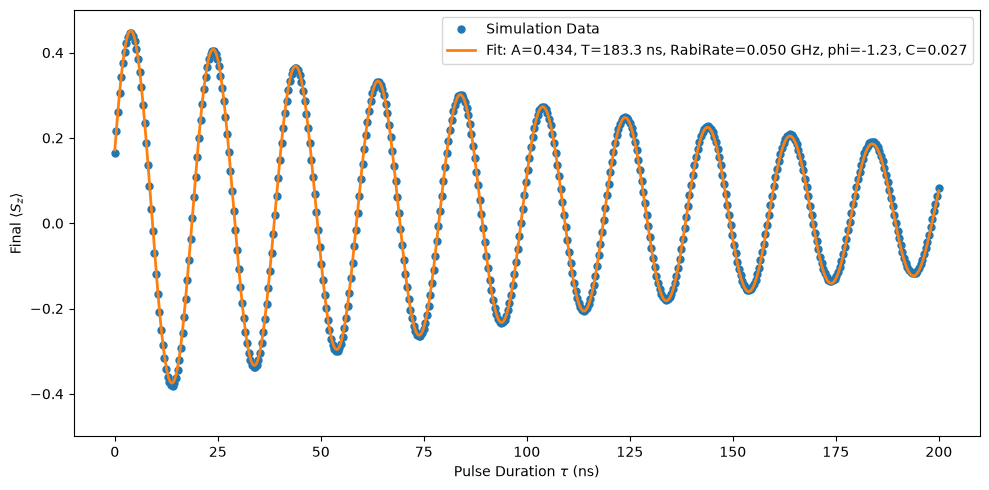

Fitted Oscillation Rate: 0.050 GHz
Detuning from resonance: 0.050 GHz
--------------------------------
fitted T2* time: 183.28 ns
Theoretical T2 time: 182.89 ns


In [11]:
tau_array = np.linspace(0, 200, 500) # ns

_, Ramsey_signal = CC.calc_Ramsey_Parallel(spin, tau_array, e_ops=None)

# Perform Oscillation Fit
x = tau_array
y = Ramsey_signal[:,2]
x_fit, y_fit, popt, perr = hf.fit_oscillation(x, y)
A_fit, T_fit, Rate_fit, phi_fit, C_fit = popt


# Plot
plt.figure(figsize=(10, 5))
plt.plot(x, y, "o", ms=5, label="Simulation Data")
plt.plot(x_fit, y_fit, "-", lw=2, label=f"Fit: A={A_fit:.3f}, T={T_fit:.1f} ns, RabiRate={Rate_fit:.3f} GHz, phi={phi_fit:.2f}, C={C_fit:.3f}")
plt.plot()
plt.xlabel(r"Pulse Duration $\tau$ (ns)")
plt.ylabel(r"Final $\langle S_{z} \rangle$")
plt.legend()
plt.ylim([-0.5,0.5])
plt.tight_layout()
plt.show()

print(f"Fitted Oscillation Rate: {Rate_fit:.3f} GHz")
print(f"Detuning from resonance: {detuning:.3f} GHz")
print("--------------------------------")
print(f"fitted T2* time: {T_fit:.2f} ns")
print(f"Theoretical T2 time: {1/(1/(2*T1) + 1/T_phi):.2f} ns")

## Ramsey for different detunings

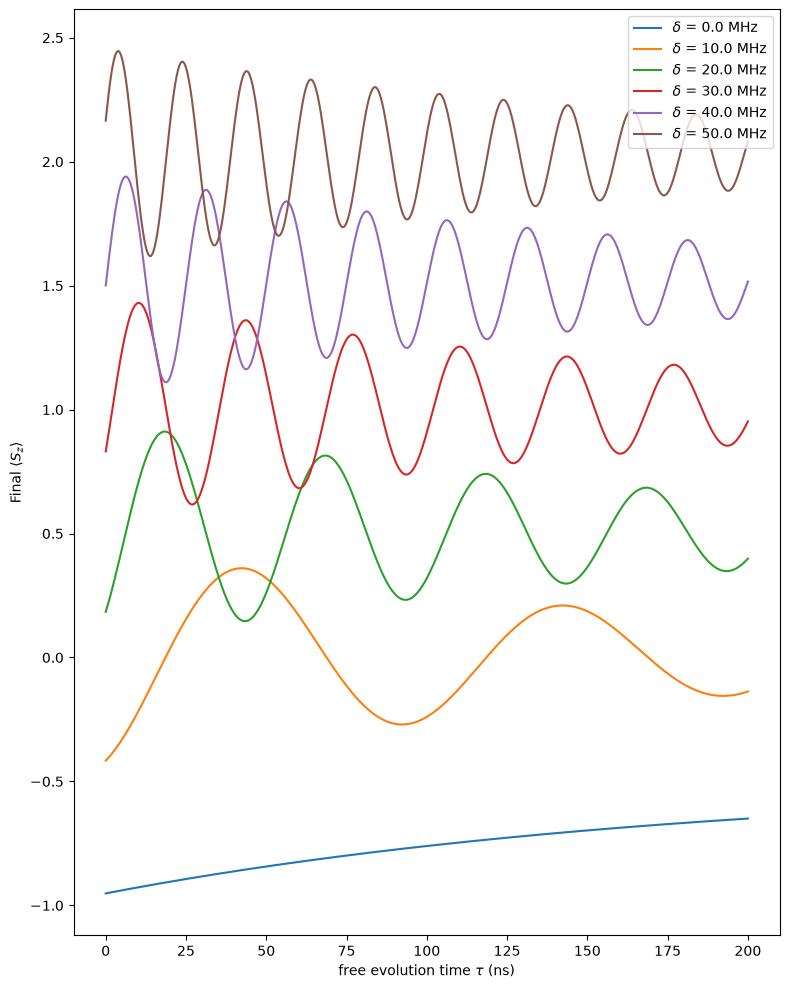

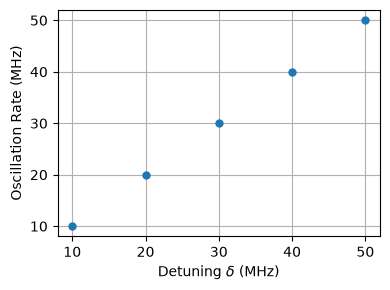

In [27]:
detunings = [0.0, 10e-3, 20e-3, 30e-3, 40e-3, 50e-3] # GHz
tau_array = np.linspace(0, 200, 500) # ns

y_offset = 0.5

Rates = []

plt.figure(figsize=(8, 10))
for i, detuning in enumerate(detunings):
    spin.f_RF = f_e + detuning
    _ = lind.initialize_thermal(spin)
    _, Ramsey_signal = CC.calc_Ramsey_Parallel(spin, tau_array, e_ops=None)

    x = tau_array
    y = Ramsey_signal[:,2]
    # Perform Oscillation Fit
    if i != 0:
        x_fit, y_fit, popt, perr = hf.fit_oscillation(x, y)
        A_fit, T_fit, Rate_fit, phi_fit, C_fit = popt

        Rates.append(Rate_fit)
    
    plt.plot(x, y + y_offset*(i-1), "-", ms=5, label=f"$\delta$ = {detuning*1e3:.1f} MHz")

    
# Plot Signals
plt.xlabel(r"free evolution time $\tau$ (ns)")
plt.ylabel(r"Final $\langle S_{z} \rangle$")
plt.legend()
plt.tight_layout()
plt.show()

# Plot the oscillation rates as a function of detuning
plt.figure(figsize=(4, 3))
detuning_axis = np.array(detunings[1:]) * 1e3
rate_axis = np.array(Rates) * 1e3
plt.plot(detuning_axis, rate_axis, "o", ms=5)
plt.xlabel(r"Detuning $\delta$ (MHz)")
plt.ylabel(r"Oscillation Rate (MHz)")
plt.tight_layout()
plt.grid()
plt.show()



## Ramsey detuning map

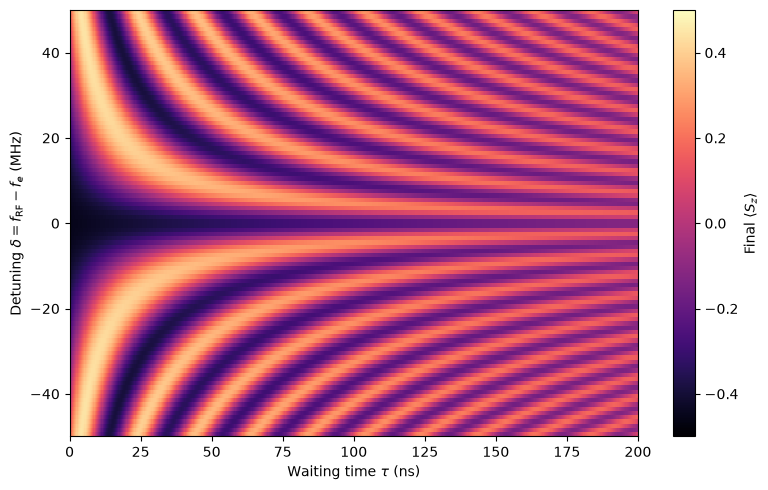

In [28]:
freq_array = np.linspace(f_e-50e-3,f_e+50e-3,100)
tau_array = np.linspace(0, 200, 500) # ns
_,_,Ramsey_map = CC.calc_RamseyDetuningMap(spin, tau_array, freq_array)

plt.figure(figsize=(8, 5))
extent = [
    tau_array[0], tau_array[-1],
    (freq_array[0]-f_e) * 1e3, (freq_array[-1]-f_e) * 1e3
]

plt.imshow(
    Ramsey_map,
    aspect='auto',
    origin='lower',
    extent=extent,
    interpolation='none',
    cmap='magma'
)

plt.xlabel(r'Waiting time $\tau$ (ns)')
plt.ylabel(r'Detuning $\delta = f_{\mathrm{RF}} - f_e$ (MHz)')
plt.clim([-0.5,0.5])
plt.colorbar(label=r'Final $\langle S_{z} \rangle$')
plt.tight_layout()
plt.show()